In [2]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA,KernelPCA
from sklearn.metrics import accuracy_score

from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans
from sklearn.datasets import make_moons
from sklearn.cluster import SpectralClustering
from sklearn.preprocessing import StandardScaler
from sklearn.mixture import GaussianMixture

df = pd.read_csv('mice-protein.csv')


In [3]:
def my_kmeans(data,k,eps=0.0001,Max_iterations=5000):
    n = data.shape[0]
    initial_indices = np.random.choice(n,k)
    centroids = data[initial_indices].astype(float).copy()
    t = 0
    while t < Max_iterations:
        t = t+1
        prev_centroids = centroids.copy()
        distances = np.linalg.norm(data[:, np.newaxis,:] - centroids[np.newaxis,:,:], axis=2)**2
        labels = np.argmin(distances, axis=1)
        # recompute centroids"Means"
        new_centroids = np.zeros_like(centroids)

        for i in range(k):
            C_i = data[labels==i]
            if len(C_i) > 0:
                new_centroids[i] = C_i.mean(axis=0)
            else:
                new_centroids[i] = prev_centroids[i]

        centroids = new_centroids

        if np.sum((centroids - prev_centroids)**2) <= eps:
            break

        return labels, centroids
            

In [4]:
# Task 1: Clustering Analysis (No Dimensionality Reduction)

# 1.1. Data preparation: Remove the label column(s); 

# impute/clean missing values; 
# standardize features. Briefly report the data shape and preprocessing steps.

numerical_df = df.drop(columns=["MouseID", "Genotype", "Treatment", "Behavior", "class"])

# Missing values are imputed using mean
imputed_df = numerical_df.fillna(numerical_df.mean())

sc = StandardScaler()
imputed_df_scaled = sc.fit_transform(imputed_df)

print(imputed_df_scaled.shape)
print(imputed_df_scaled)

(1080, 77)
[[ 0.31271112  0.5179336   2.2536689  ... -1.41662394 -1.60789061
   1.06590091]
 [ 0.35679793  0.28650133  1.8802795  ... -1.32521803 -1.54684392
   1.28029118]
 [ 0.33496588  0.45046461  2.01292763 ... -1.37325709 -1.62359464
   1.85703831]
 ...
 [-0.79192771 -0.88354273 -1.72382963 ...  1.27078193  3.11724261
   0.29352469]
 [-0.82188815 -0.8130138  -1.52387571 ...  1.88117889  3.32828966
   0.2089962 ]
 [-0.49491588 -0.62125474 -1.26845332 ...  1.92748438  3.32672533
   0.10478825]]


1080


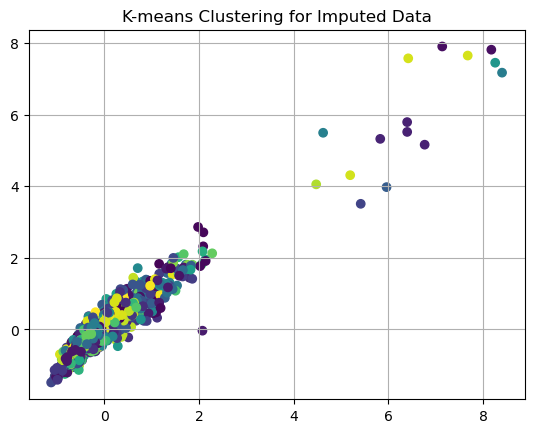

In [5]:
# 1.2. K-Means: Cluster the standardized features with k = number_of_classes 
# (use the true class count only to set k; do not use labels otherwise). 
# Run with 5 different seeds and report average metrics.

data = imputed_df_scaled
k = len(imputed_df_scaled)

# Apply K-means implementation
kmeans_labels, kmeans_mean = my_kmeans(data,k)

print(kmeans_labels.size)
# Plot data points with colors based on cluster assignments (scikit-learn)
plt.scatter(data[:, 0], data[:, 1], c=kmeans_labels)
plt.title('K-means Clustering for Imputed Data')
plt.grid()
plt.show()

In [6]:
# 1.3. Kernel K-Means: Implement or use a provided implementation of Kernel K-Means with an RBF kernel 
# (optionally: polynomial). Tune gamma (and degree if polynomial). Visualize cluster assignments.

def rbf_kernel(x, y, gamma=1.0):
    # Radial Basis Function (RBF) kernel
    return np.exp(-gamma * np.linalg.norm(x - y)**2)

def kernel_kmeans_numpy(X, n_clusters, max_iters=100, gamma=1.0):
    # Initialize cluster assignments randomly
    #np.random.seed(0)
    labels = np.random.choice(n_clusters, X.shape[0])

    for _ in range(max_iters):
        # Compute the kernel matrix
        K = np.zeros((X.shape[0], n_clusters))
        for i in range(X.shape[0]):
            for j in range(n_clusters):
                K[i, j] = rbf_kernel(X[i], X[labels == j].mean(axis=0), gamma)

        # Update cluster assignments
        new_labels = np.argmin(K, axis=1)

        # Check for convergence
        if np.all(labels == new_labels):
            break

        labels = new_labels

    return labels

kernel_kmeans_labels = kernel_kmeans_numpy(data, n_clusters=3)
print(kernel_kmeans_labels)
print(kernel_kmeans_labels.size)


[1 1 1 ... 2 2 2]
1080


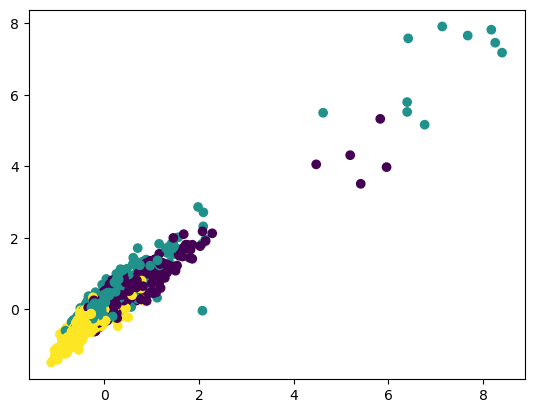

In [7]:
plt.scatter(data[:,0],data[:,1], c=kernel_kmeans_labels)

/var/folders/vh/cppsq8n14jj2nytk_4mzzmxm0000gn/T/ipykernel_885/817277232.py:25: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax1.legend()
/var/folders/vh/cppsq8n14jj2nytk_4mzzmxm0000gn/T/ipykernel_885/817277232.py:36: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax2.legend()
/var/folders/vh/cppsq8n14jj2nytk_4mzzmxm0000gn/T/ipykernel_885/817277232.py:47: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax3.legend()


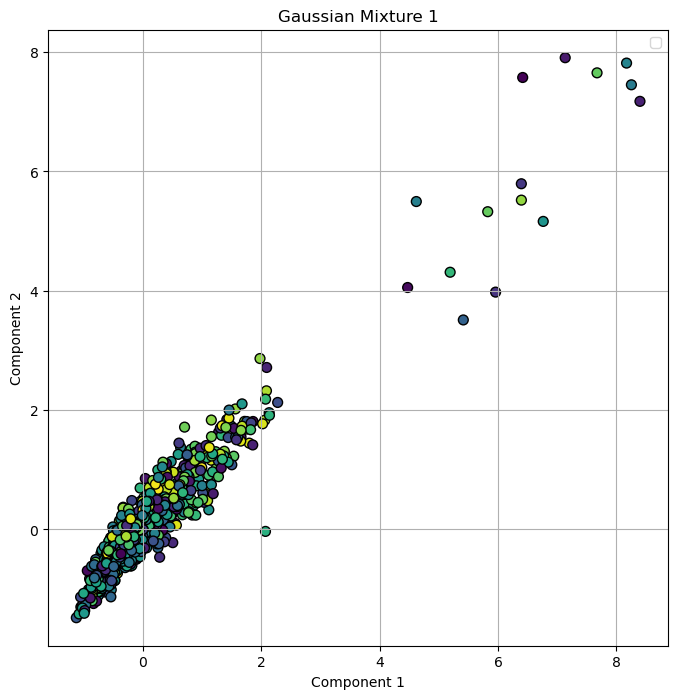

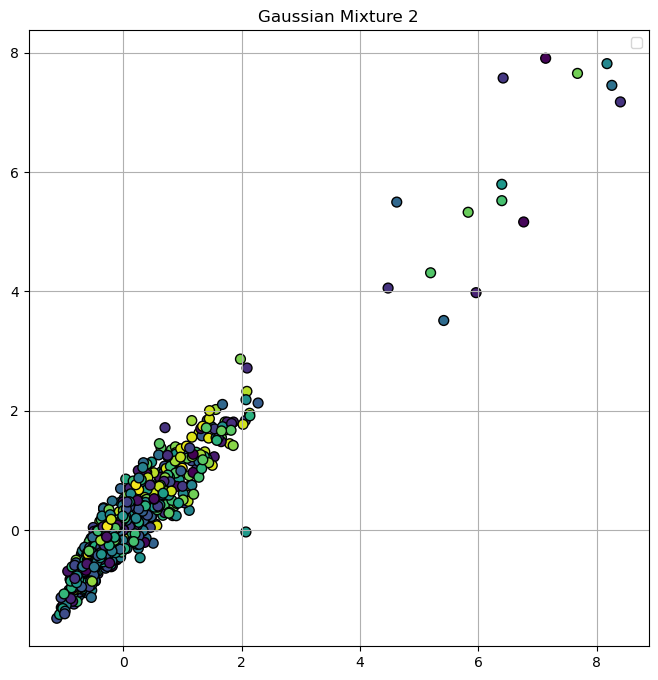

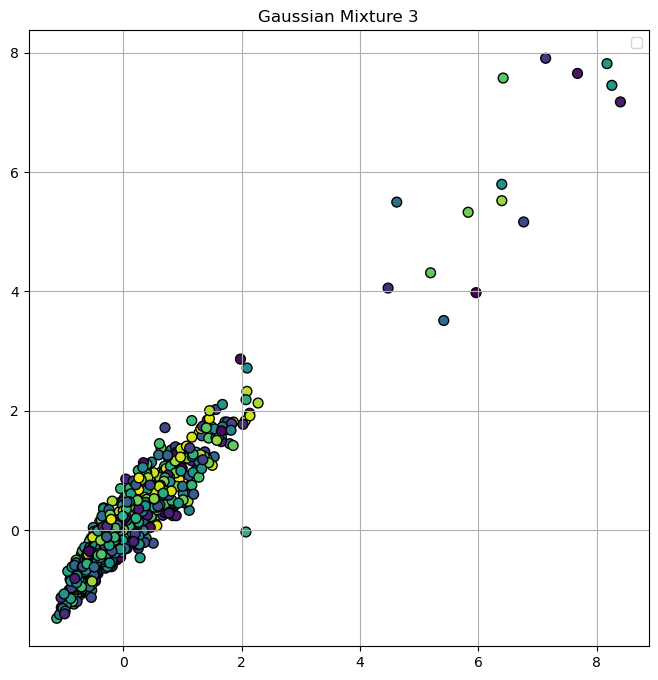

In [8]:
# 1.4. Expectation Maximization (EM): Apply a Gaussian Mixture Model (full covariance preferred) 
# with n_components = k. Run multiple seeds.

from sklearn.mixture import GaussianMixture
seeds = [0, 42, 100]

gmm1 = GaussianMixture(n_components=k, covariance_type='full', random_state=0, max_iter=100,)
gmm2 = GaussianMixture(n_components=k, covariance_type='full', random_state=42, max_iter=100,)
gmm3 = GaussianMixture(n_components=k, covariance_type='full', random_state=100, max_iter=100,)

fig1, ax1 = plt.subplots(figsize=(8, 8))

fig2, ax2 = plt.subplots(figsize=(8, 8))

fig3, ax3 = plt.subplots(figsize=(8, 8))

gmm1.fit(data)
gmm_labels1 = gmm1.predict(data)

ax1.scatter(data[:, 0], data[:, 1], c=gmm_labels1, cmap='viridis', s=50, edgecolor='k')

ax1.set_title("Gaussian Mixture 1")
ax1.set_xlabel("Component 1")
ax1.set_ylabel("Component 2")
ax1.legend()
ax1.grid(True)

gmm2.fit(data)
gmm_labels2 = gmm2.predict(data)

ax2.scatter(data[:, 0], data[:, 1], c=gmm_labels2, cmap='viridis', s=50, edgecolor='k')

ax2.set_title("Gaussian Mixture 2")
ax1.set_xlabel("Component 1")
ax1.set_ylabel("Component 2")
ax2.legend()
ax2.grid(True)

gmm3.fit(data)
gmm_labels3 = gmm3.predict(data)

ax3.scatter(data[:, 0], data[:, 1], c=gmm_labels3, cmap='viridis', s=50, edgecolor='k')

ax3.set_title("Gaussian Mixture 3")
ax1.set_xlabel("Component 1")
ax1.set_ylabel("Component 2")
ax3.legend()
ax3.grid(True)

# Display the plot
plt.show()
    


In [9]:
# 1.5 Compare methods: Report Silhouette, cluster size distribution, and (for later reference) 
# store the predicted cluster labels from each method.

from sklearn.metrics import silhouette_score, silhouette_samples

# Calculate global and per-cluster silhouette metrics
global_silhouette = silhouette_score(data, kmeans_labels)
sample_silhouette_values = silhouette_samples(data, kmeans_labels)

# Compile the Cluster Report
cluster_info = []
unique_labels = np.unique(kmeans_labels)

for label in unique_labels:
    # Filter silhouette scores for the current cluster
    cluster_scores = sample_silhouette_values[kmeans_labels == label]
    
    cluster_info.append({
        "Cluster ID": label,
        "Cluster Size": len(cluster_scores),
        "Size %": f"{(len(cluster_scores) / len(kmeans_labels)) * 100:.1f}%",
        "Avg Silhouette": round(np.mean(cluster_scores), 3)
    })

# Convert to DataFrame to print
df_report = pd.DataFrame(cluster_info)

# Display the results
print(f"=== Global Evaluation ===")
print(f"Overall Silhouette Score: {global_silhouette:.4f}\n")

print(f"=== Cluster Distribution & Quality Report ===")
print(df_report.to_string(index=False))


=== Global Evaluation ===
Overall Silhouette Score: 0.0991

=== Cluster Distribution & Quality Report ===
 Cluster ID  Cluster Size Size %  Avg Silhouette
          0             3   0.3%           0.073
          1             2   0.2%           0.129
          2             1   0.1%           0.000
          3             3   0.3%           0.208
          4             3   0.3%           0.347
          5             3   0.3%           0.590
          6             3   0.3%           0.147
          7             2   0.2%           0.163
          8             2   0.2%           0.184
          9             1   0.1%           0.000
         10             2   0.2%           0.084
         11             1   0.1%           0.000
         12             1   0.1%           0.000
         13             1   0.1%           0.000
         14             1   0.1%           0.000
         15             1   0.1%           0.000
         16             2   0.2%           0.166
         17 

In [10]:
from sklearn.metrics import silhouette_score, silhouette_samples

# Calculate global and per-cluster silhouette metrics
global_silhouette = silhouette_score(data, kernel_kmeans_labels)
sample_silhouette_values = silhouette_samples(data, kernel_kmeans_labels)

# Compile the Cluster Report
cluster_info = []
unique_labels = np.unique(kernel_kmeans_labels)

for label in unique_labels:
    # Filter silhouette scores for the current cluster
    cluster_scores = sample_silhouette_values[kernel_kmeans_labels == label]
    
    cluster_info.append({
        "Cluster ID": label,
        "Cluster Size": len(cluster_scores),
        "Size %": f"{(len(cluster_scores) / len(kernel_kmeans_labels)) * 100:.1f}%",
        "Avg Silhouette": round(np.mean(cluster_scores), 3)
    })

# Convert to DataFrame to print
df_report = pd.DataFrame(cluster_info)

# Displays the results
print(f"=== Global Evaluation ===")
print(f"Overall Silhouette Score: {global_silhouette:.4f}\n")

print(f"=== Cluster Distribution & Quality Report ===")
print(df_report.to_string(index=False))


=== Global Evaluation ===
Overall Silhouette Score: 0.1189

=== Cluster Distribution & Quality Report ===
 Cluster ID  Cluster Size Size %  Avg Silhouette
          0           279  25.8%           0.182
          1           323  29.9%           0.124
          2           478  44.3%           0.079


In [12]:
from sklearn.metrics import silhouette_score, silhouette_samples

gmm1 = GaussianMixture(n_components=k-1, covariance_type='full', random_state=0, max_iter=100,)
gmm1.fit(data)
gmm_labels1 = gmm1.predict(data)

# Calculate global and per-cluster silhouette metrics
global_silhouette = silhouette_score(data, gmm_labels1)
sample_silhouette_values = silhouette_samples(data, gmm_labels1)

# Compile the Cluster Report
cluster_info = []
unique_labels = np.unique(gmm_labels1)

for label in unique_labels:
    # Filter silhouette scores for the current cluster
    cluster_scores = sample_silhouette_values[gmm_labels1 == label]
    
    cluster_info.append({
        "Cluster ID": label,
        "Cluster Size": len(cluster_scores),
        "Size %": f"{(len(cluster_scores) / len(gmm_labels1)) * 100:.1f}%",
        "Avg Silhouette": round(np.mean(cluster_scores), 3)
    })

# Convert to DataFrame to print
df_report = pd.DataFrame(cluster_info)

# Display the results
print(f"=== Global Evaluation ===")
print(f"Overall Silhouette Score: {global_silhouette:.4f}\n")

print(f"=== Cluster Distribution & Quality Report ===")
print(df_report.to_string(index=False))


=== Global Evaluation ===
Overall Silhouette Score: 0.0006

=== Cluster Distribution & Quality Report ===
 Cluster ID  Cluster Size Size %  Avg Silhouette
          0             1   0.1%           0.000
          1             1   0.1%           0.000
          2             1   0.1%           0.000
          3             1   0.1%           0.000
          4             1   0.1%           0.000
          5             1   0.1%           0.000
          6             1   0.1%           0.000
          7             1   0.1%           0.000
          8             1   0.1%           0.000
          9             1   0.1%           0.000
         10             1   0.1%           0.000
         11             1   0.1%           0.000
         12             1   0.1%           0.000
         13             1   0.1%           0.000
         14             1   0.1%           0.000
         15             1   0.1%           0.000
         16             1   0.1%           0.000
         17 

/var/folders/vh/cppsq8n14jj2nytk_4mzzmxm0000gn/T/ipykernel_8012/530495251.py:14: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


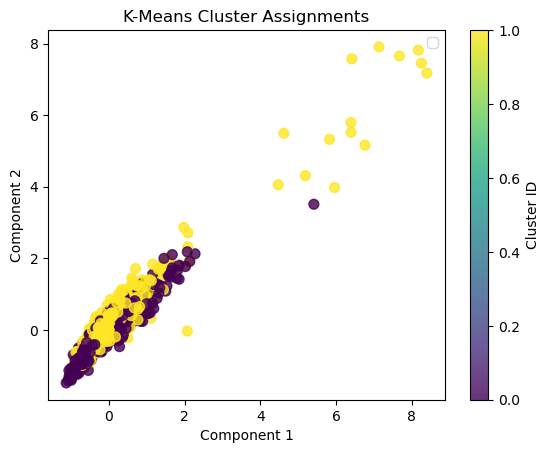

In [127]:
# 1.6. Biological interpretation: Without using the hidden labels, discuss any observable structure 
# (e.g., clusters with distinctive protein levels). Include a 2-D map colored by cluster IDs (not true labels).

# Plot data points with colors based on cluster assignments (scikit-learn)

kmeans = KMeans(n_clusters=2, random_state=0)
cluster_assignments = kmeans.fit_predict(imputed_df_scaled)
scatter = plt.scatter(data[:, 0], data[:, 1], c=cluster_assignments, cmap='viridis', s=50, alpha=0.8)

plt.title('K-Means Cluster Assignments')
plt.xlabel('Component 1')
plt.ylabel('Component 2')
plt.colorbar(scatter, label='Cluster ID')
plt.legend()
plt.show()


Number of selected components: 2
Total variance explained: 0.4231


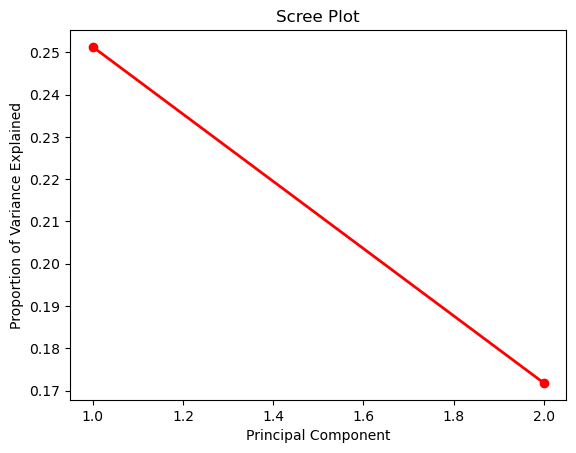

In [128]:
# Task 2: Dimensionality Reduction + Re-Clustering

# 2.1. PCA: Fit PCA (on training data where applicable; see Task 3 for splitting rules). 
# Choose components via >=95% explained variance or a fixed set (e.g., 2, 3, 5, 10, 20, 50)
# justified by a scree plot.


y_true = df["Behavior"]

y = df[["MouseID", "Genotype", "Treatment", "Behavior", "class"]]

# Splits features (X) and target (y) into 70% training and 30% testing
X_train, X_test, y_train, y_test = train_test_split(imputed_df_scaled, y, test_size=0.30)


# Scale your data (recommended for PCA)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_train)
# Fit PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)
k = X_pca.size

print(f"Number of selected components: {pca.n_components_}")
print(f"Total variance explained: {pca.explained_variance_ratio_.sum():.4f}")

PC_values = np.arange(pca.n_components_) + 1
plt.plot(PC_values, pca.explained_variance_ratio_, 'ro-', linewidth=2)
plt.title('Scree Plot')
plt.xlabel('Principal Component')
plt.ylabel('Proportion of Variance Explained')
plt.show()


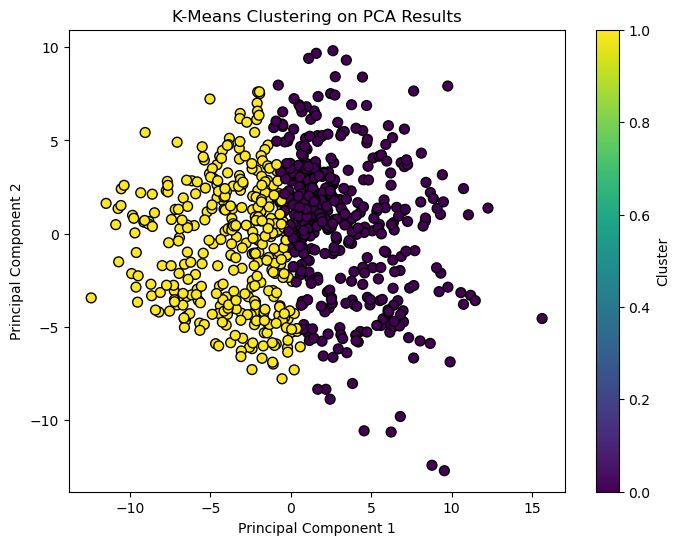

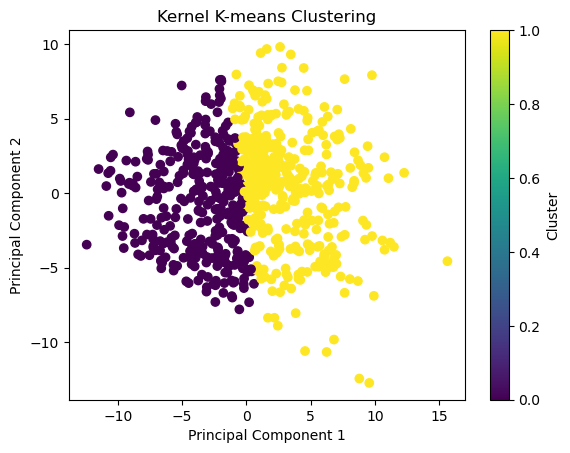

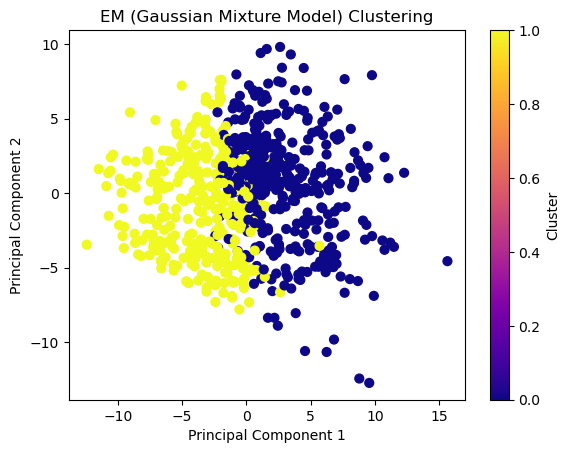

In [129]:
# 2.2. Clustering on PCA space: Repeat K-Means, Kernel K-Means, and EM on PCA-reduced features. 
# Report the same metrics and compare to Task 1.

# Apply PCA to reduce dimensionality (e.g., to 2 components)
pca_scores = X_pca

# Apply K-Means clustering on the PCA scores
kmeans = KMeans(n_clusters=2, random_state=42, n_init=10)
cluster_labels = kmeans.fit_predict(pca_scores)


# Create a DataFrame for visualization
df_pca = pd.DataFrame(pca_scores, columns=["PC1", "PC2"])
df_pca["Cluster"] = cluster_labels


# Plot the clusters
plt.figure(figsize=(8, 6))
plt.scatter(
    df_pca["PC1"],
    df_pca["PC2"],
    c=df_pca["Cluster"],
    cmap="viridis",
    edgecolor="k",
    s=50,
)
plt.title("K-Means Clustering on PCA Results")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.colorbar(label="Cluster")
plt.show()

plt.clf()

n_clusters = 2
my_labels = kernel_kmeans_numpy(pca_scores, n_clusters, gamma=1)

# Plot data points with colors based on cluster assignments
plt.scatter(pca_scores[:, 0], pca_scores[:, 1], c=my_labels, cmap='viridis')
plt.title('Kernel K-means Clustering')
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.colorbar(label="Cluster")
plt.show()

plt.clf()

# Implement EM Algorithm (via Gaussian Mixture Model)
# n_components matches the target number of clusters
gmm = GaussianMixture(n_components=2, random_state=42)
em_labels = gmm.fit_predict(X_scaled)
# Find probabilities instead of hard labels
em_probabilities = gmm.predict_proba(X_scaled)

# Plot EM (GMM)
plt.scatter(pca_scores[:, 0], pca_scores[:, 1], c=em_labels, cmap='plasma', s=40)
plt.title("EM (Gaussian Mixture Model) Clustering")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.colorbar(label="Cluster")

plt.show()



In [114]:
# 2.3. KPCA: Apply Kernel PCA (RBF; optionally polynomial). 
# Tune kernel parameters with a small grid (e.g., gamma in {1e-3, 1e-2, 1e-1, 1, 10}) 
# and reduce to {2, 3, 5, 10, 20} components.
from sklearn.decomposition import KernelPCA

kpca = KernelPCA(n_components=2, kernel='rbf')
X_kpca = kpca.fit_transform(X_scaled)
k = X_kpca.size


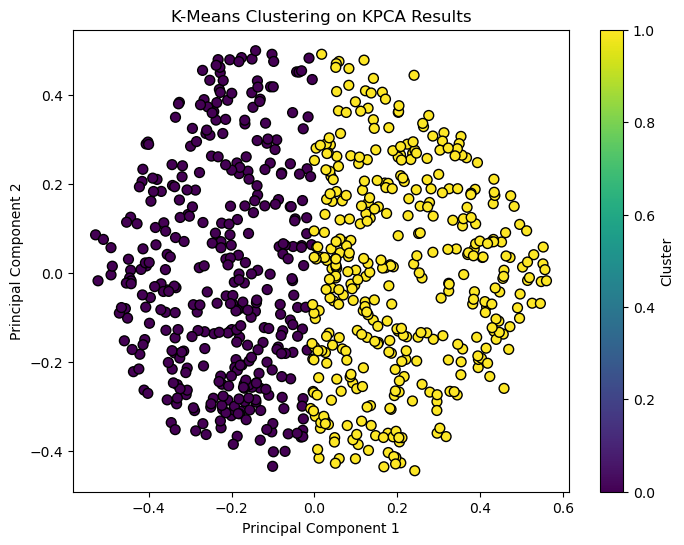

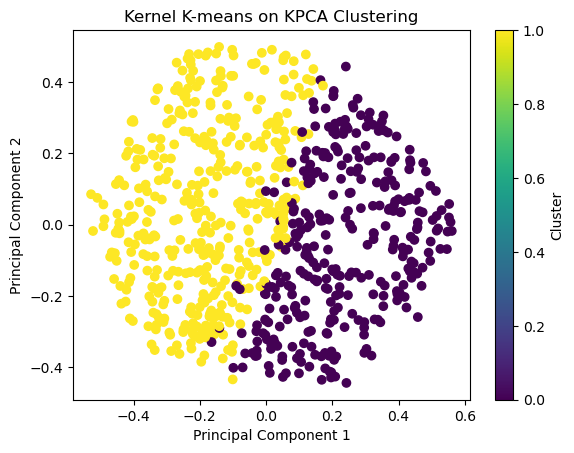

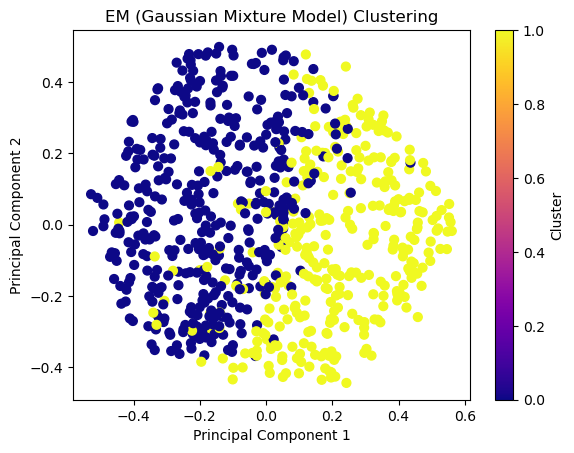

In [115]:
# 2.4. Clustering on KPCA space: Repeat K-Means, Kernel K-Means, and EM on KPCA features. 
# Report metrics and discuss when DR helped or hurt.

kpca_scores = X_kpca

# Apply K-Means clustering on the PCA scores
kmeans = KMeans(n_clusters=2, random_state=42, n_init=10)
cluster_labels = kmeans.fit_predict(kpca_scores)


# Create a DataFrame for visualization
df_kpca = pd.DataFrame(kpca_scores, columns=["PC1", "PC2"])
df_kpca["Cluster"] = cluster_labels


# Plot the clusters
plt.figure(figsize=(8, 6))
plt.scatter(df_kpca["PC1"],
    df_kpca["PC2"],
    c=df_kpca["Cluster"],
    cmap="viridis",
    edgecolor="k",
    s=50,
)
plt.title("K-Means Clustering on KPCA Results")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.colorbar(label="Cluster")
plt.show()

plt.clf()

n_clusters = 2
my_labels = kernel_kmeans_numpy(pca_scores, n_clusters, gamma=1)

# Plot data points with colors based on cluster assignments (your implementation)
plt.scatter(kpca_scores[:, 0], kpca_scores[:, 1], c=my_labels, cmap='viridis')
plt.title('Kernel K-means on KPCA Clustering')
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.colorbar(label="Cluster")
plt.show()

plt.clf()

# Implement EM Algorithm (via Gaussian Mixture Model)
# n_components matches the target number of clusters
gmm = GaussianMixture(n_components=2, random_state=42)
em_labels = gmm.fit_predict(X_scaled)
# You can also fetch probabilities instead of hard labels:
em_probabilities = gmm.predict_proba(X_scaled)

# Plot EM (GMM)
plt.scatter(kpca_scores[:, 0], kpca_scores[:, 1], c=em_labels, cmap='plasma', s=40)
plt.title("EM (Gaussian Mixture Model) Clustering")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.colorbar(label="Cluster")

plt.show()




In [116]:
# Task 3: Pseudo-Label Classification (Minimum Distance Classifier)

# 3.1. Select your best unsupervised pipeline from Tasks 1–2 
# (e.g., PCA+K-Means with specified components and seed). 
# Justify your choice based on internal metrics.

'''

I will be selecting KPCA+K-Means, since it graphs the best visual results when displaying its scatterplot 
compared to other results, with the clusters being more separate than any other graph. It also provided a 
higher overall silhouette score compared to other results.

'''

'\n\nI will be selecting KPCA+K-Means, since it graphs the best visual results when displaying its scatterplot \ncompared to other results, with the clusters being more separate than any other graph.\n\n'

In [136]:
# 3.2. Train/Test split: Split the dataset into train/test (e.g., 70/30). 
# To avoid leakage, fit scaler and DR transforms on train only, then transform test.

from sklearn.model_selection import train_test_split

X = df.drop(columns=["Behavior"])

y = df["Behavior"]

X_train, X_test, y_train, y_test = train_test_split(imputed_df_scaled, y, test_size=0.30)


In [137]:
# 3.3. Generate pseudo-labels on train: 
# Run your chosen clustering on the train features, producing pseudo-labels y_hat_train. 
# Compute class prototypes (Nearest Class Means) in the same feature space.
from sklearn.neighbors import NearestCentroid
import numpy as np


scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

kpca = KernelPCA(n_components=2, kernel='rbf', gamma=0.01, random_state=42)
X_train_kpca = kpca.fit_transform(X_train_scaled)
X_test_kpca = kpca.transform(X_test_scaled)


kmeans = KMeans(n_clusters=2, random_state=42, n_init=10)

X_train_kpca_kmeans = kmeans.fit_transform(X_train_kpca)
X_test_kpca_kmeans = kmeans.transform(X_test_kpca)

y_hat_train = kmeans.fit_predict(X_train_kpca)

print("Shape of pseudo labels:", y_hat_train.shape)
print("Unique pseudo labels generated:", np.unique(y_hat_train))



clf = NearestCentroid()
clf.fit(X_train_kpca, y_hat_train)

prototypes = clf.centroids_

print("Class Prototypes:\n", prototypes)

print(X_train_kpca_kmeans.size)
print(X_test_kpca_kmeans.size)


Shape of pseudo labels: (756,)
Unique pseudo labels generated: [0 1]
Class Prototypes:
 [[ 0.24028111  0.06302968]
 [-0.19222489 -0.05042374]]
1512
648


In [138]:
# 3.4. Classify test samples: Assign each test sample to the nearest prototype (Euclidean). 
# Report test accuracy against the pseudo-labels 
# (use optimal class permutation via the Hungarian algorithm for accuracy computation when needed).

def classify_samples(samples, prototypes):
    """
    Parameters:
    samples: Array of shape (N, D) containing N samples of D dimensions.
    prototypes: Array of shape (K, D) containing K prototype vectors.
    
    Returns:
    assignments: Array of shape (N,) containing the index (0 to K-1) of the closest prototype for each sample.
    distances: Array of shape (N,) with the exact Euclidean distance to that nearest prototype.
    """
    # Expand dimensions to calculate cross-distances via broadcasting
    # (N, 1, D) - (1, K, D) results in an array of shape (N, K, D)
    s = samples[:, np.newaxis, :]
    p = prototypes[np.newaxis, :, :]
    diff = s - p
    
    # Compute Euclidean distance across the feature dimension (axis 2)
    dist_matrix = np.linalg.norm(diff, axis=2) 
    
    # For each sample, find the index of the minimum distance
    assignments = np.argmin(dist_matrix, axis=1) 
    
    # Extract the minimum distance value for each sample
    min_distances = np.min(dist_matrix, axis=1) 
    
    return assignments, min_distances


assignments, distances = classify_samples(X_test_kpca, prototypes)

print("Assigned Prototype ID per sample:", assignments)
print("Distance to nearest prototype:   ", distances)



Assigned Prototype ID per sample: [1 0 0 0 0 0 1 1 0 0 1 1 1 1 0 0 1 1 1 1 1 0 1 1 1 0 0 1 1 0 1 0 1 1 1 0 1
 1 0 0 0 0 0 1 0 0 0 0 0 1 0 1 0 0 0 1 1 0 1 1 1 1 1 0 0 1 1 1 0 1 0 1 1 0
 1 1 1 0 0 0 0 0 1 1 1 1 0 0 1 0 1 1 1 0 0 0 0 1 0 1 1 0 1 1 1 1 1 1 1 1 0
 1 0 0 0 1 1 1 1 1 0 1 1 1 1 1 0 0 0 1 1 1 1 0 1 0 1 0 0 0 1 1 1 0 0 0 0 1
 0 1 1 1 1 0 0 0 0 0 0 1 0 1 0 1 0 0 1 1 0 1 1 1 1 0 1 1 1 1 0 1 1 1 1 0 1
 0 0 1 1 0 0 0 1 1 1 1 0 1 1 0 0 0 0 0 1 0 1 0 0 0 0 0 1 0 0 1 1 1 0 0 0 0
 1 0 0 0 1 0 1 1 1 1 1 0 1 1 1 1 0 0 1 0 1 1 1 0 1 1 0 1 1 1 0 0 0 0 0 1 0
 0 1 0 0 1 1 0 1 0 1 1 0 1 0 0 0 1 0 1 1 1 1 1 1 1 0 1 1 1 0 1 0 1 0 0 1 1
 1 1 1 1 1 0 0 0 0 1 0 1 1 0 1 1 1 0 0 1 1 1 1 1 0 0 0 0]
Distance to nearest prototype:    [0.43238737 0.21715679 0.11968547 0.16844401 0.39285647 0.16262855
 0.24121646 0.26813136 0.24960894 0.03501447 0.1704072  0.13116537
 0.16069968 0.32895109 0.27217228 0.30534387 0.07150284 0.41362824
 0.25935123 0.20661388 0.25078608 0.3959576  0.29334595 0.29401191
 0.403

In [139]:
# Task 4: Bring Back the True Labels — Final Evaluation
# 4.1. For each main setting (No-DR, PCA, KPCA), 
# compute ARI and NMI between the cluster IDs and y_true.

from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score
print(X_train_scaled.size)
print(X_test_scaled.size)

# Compute Adjusted Rand Index (ARI)
# ari_score = adjusted_rand_score(y_true, cluster_ids)

# Compute Normalized Mutual Information (NMI)
# nmi_score = normalized_mutual_info_score(y_true, cluster_ids)

# print(f"Adjusted Rand Index (ARI): {ari_score:.4f}")
# print(f"Normalized Mutual Information (NMI): {nmi_score:.4f}")

58212
24948


In [140]:
# 4.2. For your Task-3 classifier (trained on pseudo-labels), 
# compute test accuracy vs. y_true (after optimal permutation). 
# Include the confusion matrix.





In [141]:
# 4.3. Discussion: Which pipeline best aligns with the ground truth? 
# Why might PCA/KPCA help or hurt different clustering methods? 
# Comment on kernel sensitivity (gamma/degree) and any stability issues across random seeds.

'''

I believe Kmeans using KPCA space best aligns with ground truth.

PCA/KPCA can help different clustering methods by improving cluster quality and making interpretations on
graphs more clear. PCA/KPCA can also hurt different clustering methods by damaging the structure of the clusters
and interfering with the space between clusters.

From what I researched, low kernel sensitivity could merge two separate clusters into one group, while high
sensitivity could lead to identifying single data points or extremely small fluctuations as their own clusters.

'''


'\n\nI believe Kmeans using KPCA space best aligns with ground truth.\n\nPCA/KPCA can help different clustering methods by improving cluster quality and making interpretations on\ngraphs more clear. PCA/KPCA can also hurt different clustering methods by damaging the structure of the clusters\nand interfering with the space between clusters.\n\nFrom what I researched, low kernel sensitivity could merge two separate clusters into one group, while high\nsensitivity could lead to identifying single data points or extremely small fluctuations as their own clusters.\n\n'

In [143]:
"""
Conclusion
Summarize key findings from no-DR vs. DR pipelines, reflect on how reliably clusters map to biological
classes, and discuss practical guidance (e.g., when to use PCA vs. KPCA, and how pseudo-labels can or
cannot support simple classifiers in biomedical data).

PCA Kmeans and KPCA Kmeans produce the most reliable cluster map as their clusters are the most separate/divided
compared to other methods I tested. 

From what I have researched, PCA is better for linear data and can be calculated 
fast with massive datasets, while KPCA is better for nonlinear data and is calculated more slow compared to PCA.

From what I have researched, pseudo-labels can support simple classifier in biomedical data if the there are not
any incorrect predictions or large class imbalances in the dataset.

"""

'\nConclusion\nSummarize key findings from no-DR vs. DR pipelines, reflect on how reliably clusters map to biological\nclasses, and discuss practical guidance (e.g., when to use PCA vs. KPCA, and how pseudo-labels can or\ncannot support simple classifiers in biomedical data).\n\nPCA Kmeans and KPCA Kmeans produce the most reliable cluster map as their clusters are the most separate/divided\ncompared to other methods I tested. \n\nFrom what I have researched, PCA is better for linear data and can be calculated \nfast with massive datasets, while KPCA is better for nonlinear data and is calculated more slow compared to PCA.\n\nFrom what I have researched, pseudo-labels can support simple classifier in biomedical data if the there are not\nany incorrect predictions or large class imbalances in the dataset.\n\n'